# CC3092 · Laboratorio #8 — Series de tiempo y forecasting

## 0. Instalación, reproducibilidad y presupuesto computacional

In [2]:
%pip -q install "holidays>=0.60" "statsforecast>=2.0" "neuralforecast>=3.0" "lightgbm>=4.0" "chronos-forecasting>=2.0" "pyarrow>=15" "seaborn>=0.13"

In [3]:
import os, gc, io, json, math, random, time, warnings, urllib.request, zipfile
from pathlib import Path
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from IPython.display import display

SEED = 2026
N_CLIENTES = 100  # mínimo del PDF, exactamente los mismos en todos los modelos
L, H = 168, 24
QUICK_MODE = False  # True para depurar; False para la ejecución académica
RUN_NEURALFORECAST = True
RUN_CHRONOS = True
RUN_AUTOETS = True
RUN_EXTENDED = True  # sensibilidad, 3 semillas, local/global, monthly refits, H=168
EXPORT_DIR = Path('/content/resultados_lab8' if Path('/content').exists() else './resultados_lab8')
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
MAX_TRAIN_SAMPLES = 8000 if QUICK_MODE else 30000  # submuestreo de ventanas, no de clientes
MAX_VALID_SAMPLES = 3000 if QUICK_MODE else 8000
EPOCHS = 2 if QUICK_MODE else 10
NF_STEPS = 20 if QUICK_MODE else 250
BATCH_SIZE = 256
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
print(f'PyTorch={torch.__version__} | dispositivo={DEVICE} | GPU={torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"}')
print('Perfil:', 'DEPURACIÓN' if QUICK_MODE else 'ACADÉMICO', '| mínimo 100 clientes constante')

PyTorch=2.11.0+cu130 | dispositivo=cuda | GPU=Tesla T4
Perfil: ACADÉMICO | mínimo 100 clientes constante


## 1. Descarga, conversión física y selección de clientes
**Conversión correcta** (documentación oficial UCI): cada medida representa kW promediados durante 15 minutos; 1 intervalo aporta kWh = kW × 0.25. Así, para cada hora se suman las cuatro lecturas y **se divide entre 4**. Los ceros en clientes activados después de 2011 no son valores perdidos; se filtran clientes activos durante el primer día de 2012. Esto aproxima el requisito «datos completos desde 2012-01-01» sin asumir que todo cero sea dato faltante.

**Cambio de horario:** UCI preservó 96 registros por día, incluso en las fechas DST: en marzo puso ceros en la hora omitida; en octubre concentró dos horas reales en un bloque. Se mantiene esa convención original de **24 horas civiles etiquetadas por día** para que los 92 días de prueba tengan H=24. No aplicar `tz_localize` ni interpolar la hora de marzo, pues modificaría la definición del dataset. Se marcan explícitamente ambos días cada año como anomalías estructurales.

In [4]:
URL = 'https://archive.ics.uci.edu/static/public/321/electricityloaddiagrams20112014.zip'
ROOT = Path('/content' if Path('/content').exists() else '.')
ZIP_FILE = ROOT/'electricity.zip'; DATA_FILE = ROOT/'LD2011_2014.txt'
if not DATA_FILE.exists():
    if not ZIP_FILE.exists():
        print('Descargando dataset UCI (≈250 MB)...')
        urllib.request.urlretrieve(URL, ZIP_FILE)
    with zipfile.ZipFile(ZIP_FILE) as z:
        candidates = [x for x in z.namelist() if x.endswith('LD2011_2014.txt') and not x.startswith('__MACOSX')]
        assert len(candidates) == 1, 'Archivo LD2011_2014.txt no encontrado en ZIP'
        print('Extrayendo archivo de ≈678 MB...')
        with z.open(candidates[0]) as src, open(DATA_FILE, 'wb') as dst:
            import shutil; shutil.copyfileobj(src, dst)

raw = pd.read_csv(DATA_FILE, sep=';', decimal=',', index_col=0, parse_dates=True, dtype=np.float32)
raw.index = pd.to_datetime(raw.index)
raw = raw.sort_index()
assert raw.index.is_unique, 'Investigar marcas de tiempo repetidas'
print('Datos originales (cuartos de hora × clientes):', raw.shape)

first_day = raw.loc['2012-01-01 00:00:00':'2012-01-01 23:45:00']
active = first_day.columns[(first_day.fillna(0).gt(0).any(axis=0)) & raw.notna().all(axis=0)]
assert len(active) >= N_CLIENTES, f'Solo {len(active)} clientes elegibles: revisar la regla'
rng = np.random.default_rng(SEED)
clientes = sorted(rng.choice(active.to_numpy(), size=N_CLIENTES, replace=False).tolist())
print('Clientes activos y sin NaN:', len(active), '| clientes elegidos:', len(clientes))
print('Primeros clientes:', clientes[:8])

# El promedio de potencia en la hora × duración de 1h equivale a sumar kW/4.
hourly = (raw[clientes].resample('h').sum(min_count=4) / 4.0).astype(np.float32)
hourly = hourly.loc['2012-01-01 00:00:00':'2014-12-31 23:00:00']
expected_idx = pd.date_range('2012-01-01', '2014-12-31 23:00:00', freq='h')
assert hourly.index.equals(expected_idx), 'Se detectaron horas faltantes o adicionales'
assert hourly.notna().all().all(), 'Hay NaN horarios que exigen análisis'
assert (hourly.to_numpy() >= 0).all(), 'Existen consumos negativos'
del raw; gc.collect()
print('Panel horario:', hourly.shape, '| observaciones en panel:', hourly.size)
print('Horas por cliente:', len(hourly), '| consumo kWh (promedio global):', round(hourly.to_numpy().mean(), 4))

Descargando dataset UCI (≈250 MB)...
Extrayendo archivo de ≈678 MB...
Datos originales (cuartos de hora × clientes): (140256, 370)
Clientes activos y sin NaN: 320 | clientes elegidos: 100
Primeros clientes: ['MT_002', 'MT_004', 'MT_006', 'MT_021', 'MT_027', 'MT_028', 'MT_036', 'MT_040']
Panel horario: (26304, 100) | observaciones en panel: 2630400
Horas por cliente: 26304 | consumo kWh (promedio global): 898.0347


In [5]:
# Las transiciones son el último domingo de marzo/octubre cada año (Portugal continental).
def last_sunday(year, month):
    end = pd.Timestamp(year, month, 1) + pd.offsets.MonthEnd(0)
    return end - pd.Timedelta(days=(end.weekday()+1)%7)
dst_days = [(y, str(last_sunday(y, 3).date()), str(last_sunday(y, 10).date())) for y in (2012, 2013, 2014)]
print('Año / salto primavera / cambio otoño:')
for row in dst_days: print(row)
# No recuperamos energía horaria real en el bloque doble de octubre: limitación explícita.

Año / salto primavera / cambio otoño:
(2012, '2012-03-25', '2012-10-28')
(2013, '2013-03-31', '2013-10-27')
(2014, '2014-03-30', '2014-10-26')


## 2. EDA, feriados y covariables conocidas a futuro
Codificamos hora, día de la semana y mes con seno/coseno y feriado con un indicador binario (Portugal). No se usan consumos futuros observados como entrada.

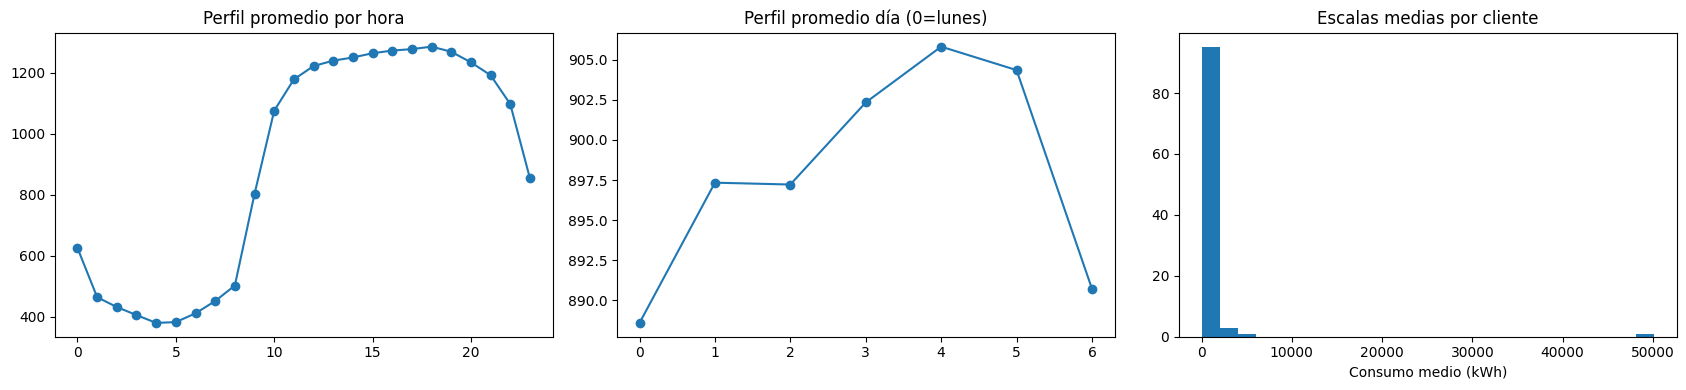

Escala media de consumo por cliente (kWh): {'min': 2.459451675415039, 'median': 159.49635314941406, 'max': 50132.25390625}
Promedio diario global de los feriados seleccionados:


,kWh_h_promedio
2012-01-01,552.931091
2012-12-25,546.639648
2013-01-01,523.471924
2013-12-25,492.037354
2014-01-01,507.366608
2014-12-25,439.501251


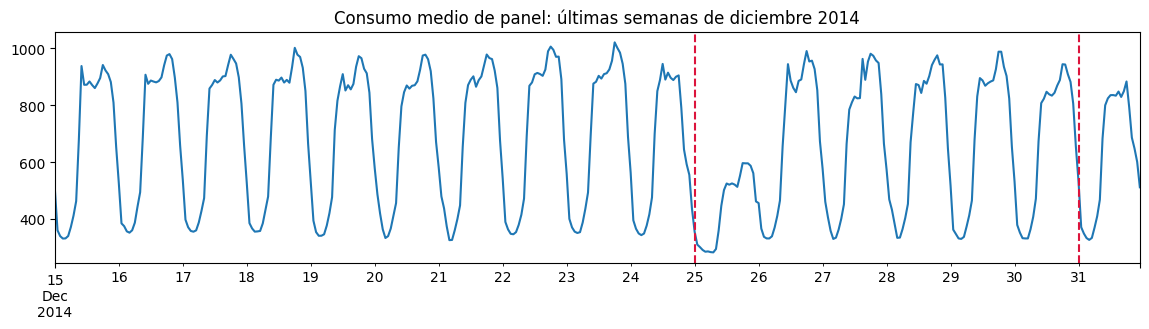

In [6]:
pt_holidays = holidays.country_holidays('PT', years=[2012, 2013, 2014])
calendar = pd.DataFrame(index=hourly.index)
calendar['hour'] = calendar.index.hour.astype(int)
calendar['weekday'] = calendar.index.dayofweek.astype(int)
calendar['month'] = calendar.index.month.astype(int)
calendar['holiday'] = np.fromiter((int(ts.date() in pt_holidays) for ts in calendar.index), dtype=np.int8)
for name, period, base in [('hour',24,0), ('weekday',7,0), ('month',12,1)]:
    angle = 2*np.pi*(calendar[name].to_numpy()-base)/period
    calendar[f'{name}_sin'] = np.sin(angle).astype('float32')
    calendar[f'{name}_cos'] = np.cos(angle).astype('float32')
CAL_COLS = ['hour_sin','hour_cos','weekday_sin','weekday_cos','month_sin','month_cos','holiday']
cal_np = calendar[CAL_COLS].to_numpy(dtype=np.float32)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
mean_agg = hourly.mean(axis=1)
mean_agg.groupby(mean_agg.index.hour).mean().plot(ax=axes[0], marker='o', title='Perfil promedio por hora')
mean_agg.groupby(mean_agg.index.dayofweek).mean().plot(ax=axes[1], marker='o', title='Perfil promedio día (0=lunes)')
axes[2].hist(hourly.mean(axis=0).to_numpy(), bins=25)
axes[2].set(title='Escalas medias por cliente', xlabel='Consumo medio (kWh)')
plt.tight_layout(); plt.show()
scales = hourly.mean(axis=0)
print('Escala media de consumo por cliente (kWh):', scales.agg(['min','median','max']).to_dict())
# Día de Navidad y Año Nuevo vs resto de diciembre/enero.
special = mean_agg.loc[mean_agg.index.normalize().isin([
    pd.Timestamp(f'{y}-{m:02d}-{d:02d}') for y in (2012,2013,2014) for m,d in [(1,1),(12,25)]
])]
print('Promedio diario global de los feriados seleccionados:')
display(special.resample('D').mean().dropna().to_frame('kWh_h_promedio'))
ax = mean_agg.loc['2014-12-15':'2014-12-31'].plot(figsize=(14,3), title='Consumo medio de panel: últimas semanas de diciembre 2014')
for day in ['2014-12-25', '2014-12-31']: ax.axvline(pd.Timestamp(day), ls='--', color='crimson')
plt.show()

## 3. Partición temporal, normalización y Dataset de ventanas
Estandarización **por serie** usando exclusivamente el bloque de entrenamiento, con media y desviación estándar por cliente. La misma transformación se reutiliza en validación y prueba; la inversión devuelve kWh. El denominador MASE usa la diferencia estacional de 168 h **calculada solo en entrenamiento**. El contexto de validación/prueba puede extenderse al bloque temporal precedente (ya observado); solo el **objetivo** de cada ventana debe caer íntegramente dentro de su bloque.

In [7]:
idx = hourly.index
T0 = idx.get_loc(pd.Timestamp('2012-01-01 00:00:00'))
T_TR = idx.get_loc(pd.Timestamp('2014-07-01 00:00:00'))
T_VA = idx.get_loc(pd.Timestamp('2014-10-01 00:00:00'))
T_END = len(idx)
Y = hourly.to_numpy(dtype=np.float32).T.copy()  # [n_clientes, n_horas]
MEAN = Y[:, T0:T_TR].mean(axis=1).astype(np.float32)
STD = Y[:, T0:T_TR].std(axis=1).astype(np.float32)
STD = np.maximum(STD, 1e-3)
Z = ((Y - MEAN[:,None])/STD[:,None]).astype(np.float32)
# Escala estacional: denominador distinto por serie; 168h de rezago.
MASE_DEN = np.mean(np.abs(Y[:,168:T_TR] - Y[:,:T_TR-168]), axis=1)
MASE_DEN = np.where(MASE_DEN > 1e-8, MASE_DEN, np.nan)
assert np.isfinite(Z).all()
assert T_END-T_VA == 92*24
splits = {'train':(T0,T_TR), 'val':(T_TR,T_VA), 'test':(T_VA,T_END)}
print('Bloques (horas):', {k:b-a for k,(a,b) in splits.items()})

class SlidingPanelDataset(Dataset):
    """X: (L, 1+n_cal), y: (H,), future_calendar: (H,n_cal).
    El orden es serie > origen; n_ventanas=series*n_orígenes.
    """
    def __init__(self, which='train', lookback=168, horizon=24, stride=1, series_ids=None):
        self.lookback, self.horizon, self.which = lookback, horizon, which
        a,b = splits[which]
        self.origins = np.arange(max(a,lookback), b-horizon+1, stride, dtype=np.int32)
        self.series_ids = np.arange(len(clientes)) if series_ids is None else np.asarray(series_ids)
    def __len__(self): return len(self.series_ids)*len(self.origins)
    def __getitem__(self, item):
        nw = len(self.origins)
        ci, origin = int(self.series_ids[item//nw]), int(self.origins[item%nw])
        past = Z[ci, origin-self.lookback:origin,None]
        x = np.concatenate([past, cal_np[origin-self.lookback:origin]], axis=1)
        f = cal_np[origin:origin+self.horizon]
        target = Z[ci,origin:origin+self.horizon]
        return {'x':torch.from_numpy(x), 'future_cov':torch.from_numpy(f.copy()),
                'y':torch.from_numpy(target.copy()), 'client_idx':torch.tensor(ci, dtype=torch.long),
                'origin':torch.tensor(origin, dtype=torch.long)}

for split in ('train','val','test'):
    ds = SlidingPanelDataset(split,L,H,1)
    print(f'{split}: {len(ds):,} ventanas | {len(ds.origins):,} orígenes horarios × {len(clientes)} clientes')
example = SlidingPanelDataset('train')[0]
assert example['x'].shape == (L,1+len(CAL_COLS)) and example['y'].shape == (H,)
assert example['future_cov'].shape == (H,len(CAL_COLS))
print('Shape de una muestra:', {k:tuple(v.shape) for k,v in example.items()})

Bloques (horas): {'train': 21888, 'val': 2208, 'test': 2208}
train: 2,169,700 ventanas | 21,697 orígenes horarios × 100 clientes
val: 218,500 ventanas | 2,185 orígenes horarios × 100 clientes
test: 218,500 ventanas | 2,185 orígenes horarios × 100 clientes
Shape de una muestra: {'x': (168, 8), 'future_cov': (24, 7), 'y': (24,), 'client_idx': (), 'origin': ()}


### Auditoría explícita de las cuatro fugas
- **Split aleatorio de ventanas:** prohibido; los índices del *target* están contenidos enteramente en train/val/test.
- **Escalador sobre toda la serie:** prohibido; `MEAN`, `STD` y `MASE_DEN` se ajustan únicamente antes de 2014-07-01.
- **Early stopping con test:** prohibido; selección sobre las fechas de julio-septiembre exclusivamente.
- **Covariables desalineadas:** los valores futuros son únicamente calendario ya conocido; se prueba la correspondencia origen ↔ timestamp y la no superposición de target/contexto.

In [8]:
# Pruebas automatizadas (si una falla, NO continuar).
for name,(a,b) in splits.items():
    ds = SlidingPanelDataset(name, L, H, 1)
    assert ds.origins.min() >= a
    assert ds.origins.max()+H <= b
    assert ds.origins.min() >= L
    assert np.all(np.diff(ds.origins) == 1)
assert not np.shares_memory(Y[:,:T_TR],Y[:,T_VA:])
assert np.allclose(MEAN, Y[:,:T_TR].mean(axis=1))
assert np.allclose(STD, np.maximum(Y[:,:T_TR].std(axis=1),1e-3))
for o in [T_TR,T_VA,T_VA+24,T_END-H]:
    assert idx[o-1]+pd.Timedelta(hours=1)==idx[o]
    assert np.allclose(cal_np[o:o+H], calendar.iloc[o:o+H][CAL_COLS].to_numpy())
    assert len(set(calendar.iloc[o:o+H].index)) == H
print('4 auditorías de fuga: APROBADAS; test bloqueado para tuneo.')

4 auditorías de fuga: APROBADAS; test bloqueado para tuneo.


## 4. Métricas y backtesting común
**Una sola interfaz** `backtest(modelo, bloque)` evalúa cualquier predictor que implemente `predict(origin, horizon)` y produzca matriz `(n_clientes,H)` en **kWh**. En test se consideran exactamente 92 orígenes a las 00:00. Los modelos pueden consultar las horas previas a cada origen, nunca los objetivos del origen actual. El MAPE sobre y≈0 es inestable: se reporta NaN cuando y=0 y la fracción de ceros.

**MASE**: MAE de predicción dividido por MAE del naïve estacional de 168 horas **sobre entrenamiento** de cada cliente. **WAPE**: suma absoluta de errores / suma absoluta real de todo el panel, no media de WAPE por cliente.

In [9]:
def point_metrics(y_true, y_pred, mase_den=MASE_DEN):
    # ambas matrices [origen, cliente, horizonte]
    e = np.asarray(y_pred,dtype=np.float64)-np.asarray(y_true,dtype=np.float64)
    a = np.abs(e); yt = np.asarray(y_true,dtype=np.float64)
    den = mase_den[None,:,None]
    mask = np.abs(yt) > 1e-8
    mape = float(np.mean(100*a[mask]/np.abs(yt[mask]))) if mask.any() else np.nan
    return {'MAE':float(a.mean()), 'RMSE':float(np.sqrt(np.mean(e**2))),
            'WAPE':float(100*a.sum()/np.maximum(np.abs(yt).sum(),1e-10)),
            'MAPE':mape, 'MASE':float(np.nanmean(a/den)),
            'fraccion_ceros':float((~mask).mean())}

class ForecastResult:
    def __init__(self, name, origins, truth, pred, seconds, q10=None, q90=None):
        self.name,self.origins,self.y,self.pred,self.seconds = name,origins,truth,pred,seconds
        self.q10,self.q90 = q10,q90
    def metrics(self):
        d = point_metrics(self.y,self.pred)
        if self.q10 is not None and self.q90 is not None:
            d['pinball_P10_P90'] = float((pinball(self.y,self.q10,.1)+pinball(self.y,self.q90,.9))/2)
            d['cobertura_P10_P90'] = float(np.mean((self.y>=self.q10)&(self.y<=self.q90)))
        return d

def pinball(y, qhat, tau):
    delta=np.asarray(y)-np.asarray(qhat)
    return np.mean(np.maximum(tau*delta,(tau-1)*delta))

def daily_origins(which):
    a,b=splits[which]
    return np.arange(a,b-H+1,24,dtype=np.int32)

RESULTS = {}
VALIDATION = {}
MODEL_META = {}

def backtest(modelo, which='test', name=None, save=True, horizon=H):
    a,b=splits[which]
    origins=np.arange(a,b-horizon+1,24,dtype=np.int32)
    truth=np.stack([Y[:,o:o+horizon] for o in origins],axis=0)
    preds, lows, highs=[],[],[]
    t0=time.perf_counter()
    for o in origins:
        out=modelo.predict(int(o), horizon=horizon)
        if isinstance(out,tuple):
            p,qlo,qhi=out
            lows.append(np.asarray(qlo,dtype=np.float32)); highs.append(np.asarray(qhi,dtype=np.float32))
        else: p=out
        p=np.asarray(p,dtype=np.float32)
        if p.shape!=(len(clientes),horizon):
            raise ValueError(f'Predicción {name or modelo}: forma {p.shape} ≠ {(len(clientes),horizon)}')
        if not np.isfinite(p).all(): raise ValueError('El modelo produjo NaN/Inf')
        preds.append(p)
    elapsed=time.perf_counter()-t0
    res=ForecastResult(name or type(modelo).__name__,origins,truth,np.stack(preds),elapsed,
                       np.stack(lows) if lows else None,np.stack(highs) if highs else None)
    if save:
        (RESULTS if which=='test' else VALIDATION)[res.name]=res
    return res

class NaiveAdapter:
    def __init__(self, period=None):
        self.period=period
    def predict(self, origin, horizon=24):
        if self.period is None: return np.repeat(Y[:,origin-1:origin],horizon,axis=1)
        offset = np.arange(horizon)%self.period
        return Y[:,origin-self.period+offset]

# Implementación vectorizada matemáticamente idéntica a StatsForecast Naive/SeasonalNaive
# y adaptada al mismo protocolo sin reentrenar pesos.
baselines={
    'Naive':NaiveAdapter(),
    'SeasonalNaive24':NaiveAdapter(24),
    'SeasonalNaive168':NaiveAdapter(168),
}
for name, adapter in baselines.items():
    r=backtest(adapter,'val',name)
    print('VALIDACIÓN',name, r.metrics())
for name, adapter in baselines.items():
    r=backtest(adapter,'test',name)
    MODEL_META[name]={'familia':'Baseline/StatsForecast-equivalente','L':168 if '168' in name else 24,
                      'estrategia':'Regla fija','covariables':False,'parametros':0,'entrenables':0,
                      'entrenamiento_s':0.,'hardware':'CPU'}
    print('PRUEBA',name, r.metrics())

VALIDACIÓN Naive {'MAE': 586.1682525878642, 'RMSE': 4931.379135804396, 'WAPE': 51.02353882822352, 'MAPE': 43.19908384388074, 'MASE': 3.772670997490473, 'fraccion_ceros': 0.007155797101449275}
VALIDACIÓN SeasonalNaive24 {'MAE': 78.31989988376858, 'RMSE': 773.9653221198072, 'WAPE': 6.81742560280171, 'MAPE': 19.428072185798108, 'MASE': 0.9473751846591394, 'fraccion_ceros': 0.007155797101449275}
VALIDACIÓN SeasonalNaive168 {'MAE': 117.1255505509248, 'RMSE': 1327.3363656366294, 'WAPE': 10.195298107545268, 'MAPE': 14.713264492168198, 'MASE': 1.018129133883875, 'fraccion_ceros': 0.007155797101449275}
PRUEBA Naive {'MAE': 337.74612851609356, 'RMSE': 2789.965591659982, 'WAPE': 42.84507084816503, 'MAPE': 40.24072099913738, 'MASE': 3.310405923113772, 'fraccion_ceros': 0.014067028985507246}
PRUEBA SeasonalNaive24 {'MAE': 69.41020449096634, 'RMSE': 626.6065501127785, 'WAPE': 8.80509020804178, 'MAPE': 18.413510019993172, 'MASE': 1.0099195015715972, 'fraccion_ceros': 0.014067028985507246}
PRUEBA Seas

## 5. Implementaciones propias: MLP, DLinear, NLinear, LSTM y encoder–decoder
Las arquitecturas originales comparten interfaz `(x, future_cov) → 24 valores normalizados`. Se usan dos LSTM multi-paso: pronóstico **directo** de 24 salidas y pronóstico **autorregresivo** de 1 paso realimentado. `Seq2Seq` recibe calendario conocido en su decoder; durante entrenamiento puede usar *teacher forcing*, pero **nunca** en validación o prueba.

En el trabajo escrito: `nn.LSTM(input_size,hidden_size,num_layers,batch_first,dropout)` devuelve `output:[B,L,D*hidden]`, `h_n:[D*capas,B,hidden]` y `c_n` con igual forma. `nn.GRU` devuelve `output` y `h_n`, **sin** `c_n`. En un modelo Conv1d dilatado causal con `k` fijo, el campo receptivo es `R=1+(k-1)*sum(dilations)` para una convolución por bloque; con dos convoluciones por bloque se duplican los incrementos. Un Transformer encoder usa `d_model`, `nhead` y `dim_feedforward`; se suman codificaciones posicionales al embedding para preservar orden temporal.

In [10]:
N_CAL = len(CAL_COLS)

class MultiOutputMLP(nn.Module):
    def __init__(self,L=168,H=24,hidden=128,dropout=.1):
        super().__init__(); self.L,self.H=L,H
        self.net=nn.Sequential(nn.Flatten(),nn.Linear(L*(1+N_CAL)+H*N_CAL,hidden),
           nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,hidden),nn.ReLU(),nn.Linear(hidden,H))
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        return self.net(torch.cat([x.flatten(1),future_cov.flatten(1)],dim=1))

class DLinearOwn(nn.Module):
    def __init__(self,L=168,H=24,kernel=25):
        super().__init__(); self.L,self.H=L,H; self.kernel=kernel
        self.trend=nn.Linear(L,H); self.season=nn.Linear(L,H)
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        z=x[:,:,0]
        pad=(self.kernel-1)//2
        sm=nn.functional.avg_pool1d(nn.functional.pad(z[:,None,:],(pad,pad),mode='replicate'), self.kernel, stride=1).squeeze(1)
        return self.season(z-sm)+self.trend(sm)

class NLinearOwn(nn.Module):
    def __init__(self,L=168,H=24):
        super().__init__(); self.L,self.H=L,H; self.linear=nn.Linear(L,H)
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        z=x[:,:,0]; last=z[:,-1:]
        return self.linear(z-last)+last

class LSTMDirect(nn.Module):
    def __init__(self,L=168,H=24,hidden=64,layers=1,dropout=0.1):
        super().__init__(); self.L,self.H=L,H
        self.encoder=nn.LSTM(1+N_CAL,hidden,num_layers=layers,batch_first=True,
                             dropout=dropout if layers>1 else 0.0)
        self.head=nn.Sequential(nn.Dropout(dropout),nn.Linear(hidden+H*N_CAL,128),nn.ReLU(),nn.Linear(128,H))
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        _,(h,_)=self.encoder(x)
        return self.head(torch.cat([h[-1],future_cov.flatten(1)],dim=1))

class LSTMDecoder(nn.Module):
    def __init__(self,L=168,H=24,hidden=64,seq2seq=False):
        super().__init__(); self.L,self.H,self.seq2seq=L,H,seq2seq
        self.encoder=nn.LSTM(1+N_CAL,hidden,batch_first=True)
        self.decoder=nn.LSTMCell(1+(N_CAL if seq2seq else 0),hidden)
        self.head=nn.Linear(hidden,1)
    def forward(self,x,future_cov,y_teacher=None,teacher_forcing_ratio=0):
        _,(h,c)=self.encoder(x)
        h,c=h[-1],c[-1]
        prev=x[:,-1,0:1]; outputs=[]
        for t in range(self.H):
            dec_in=torch.cat([prev,future_cov[:,t,:]],dim=1) if self.seq2seq else prev
            h,c=self.decoder(dec_in,(h,c))
            p=self.head(h)
            outputs.append(p)
            if self.training and y_teacher is not None and teacher_forcing_ratio>0:
                selector=(torch.rand(p.shape[0],1,device=p.device)<teacher_forcing_ratio)
                prev=torch.where(selector,y_teacher[:,t:t+1],p)
            else: prev=p
        return torch.cat(outputs,dim=1)

FACTORIES = {
 'MLP':lambda l,h:MultiOutputMLP(l,h),
 'DLinear':lambda l,h:DLinearOwn(l,h),
 'NLinear':lambda l,h:NLinearOwn(l,h),
 'LSTM_Direct':lambda l,h:LSTMDirect(l,h),
 'LSTM_Autoregresiva':lambda l,h:LSTMDecoder(l,h,seq2seq=False),
 'Seq2Seq':lambda l,h:LSTMDecoder(l,h,seq2seq=True),
}
for name, factory in FACTORIES.items():
    net=factory(L,H).to(DEVICE)
    with torch.no_grad():
        zhat=net(torch.zeros(2,L,1+N_CAL,device=DEVICE),torch.zeros(2,H,N_CAL,device=DEVICE))
    assert zhat.shape==(2,H)
    print(f'{name:22s} parámetros = {sum(p.numel() for p in net.parameters()):,}')
    del net

MLP                    parámetros = 213,272
DLinear                parámetros = 8,112
NLinear                parámetros = 4,056
LSTM_Direct            parámetros = 51,864
LSTM_Autoregresiva     parámetros = 36,161
Seq2Seq                parámetros = 37,953


### Entrenamiento y early stopping
Se selecciona la mejor época **solo por MAE en validación**; se registra también MASE de validación, pérdida por época, tiempo, parámetros y memoria pico CUDA. El conjunto de ventanas tiene stride=1; para limitar tiempo en Colab se muestrean hasta `MAX_TRAIN_SAMPLES` por corrida, con semilla fija. El ajuste final reinicia los pesos y entrena sobre **train+val hasta 2014-09-30** durante el número de épocas seleccionado. No se accede a la prueba durante selección.

In [11]:
def make_dataset(lookback, until, start=0, horizon=H, validation=False, series_ids=None):
    ds=SlidingPanelDataset('val' if validation else 'train',lookback,horizon,1,series_ids)
    low=max(lookback, start if not validation else T_TR)
    high=until-horizon
    ds.origins=np.arange(low,high+1,1,dtype=np.int32)
    return ds

def sampled_loader(ds, n, batch_size=BATCH_SIZE, shuffle=True, seed=SEED):
    size=min(len(ds),int(n))
    ix=np.random.default_rng(seed).choice(len(ds),size=size,replace=False)
    subset=Subset(ds,ix.tolist())
    return DataLoader(subset,batch_size=batch_size,shuffle=shuffle,num_workers=0,pin_memory=(DEVICE.type=='cuda'))

def fit_own(net, train_ds, val_ds=None, epochs=EPOCHS, seed=SEED, lr=1e-3,
            train_samples=MAX_TRAIN_SAMPLES, val_samples=MAX_VALID_SAMPLES,
            early_stop=True, verbose=True):
    set_seed(seed)
    net=net.to(DEVICE)
    opt=torch.optim.Adam(net.parameters(),lr=lr)
    tr_loader=sampled_loader(train_ds,train_samples,shuffle=True,seed=seed)
    va_loader=sampled_loader(val_ds,val_samples,shuffle=False,seed=seed) if val_ds is not None else None
    best,wait,state,best_epoch=float('inf'),0,None,epochs
    logs=[]; begin=time.perf_counter()
    for epoch in range(1,epochs+1):
        if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
        tick=time.perf_counter(); net.train(); loss_acc,n_acc=0,0
        for batch in tr_loader:
            xb,fb,yb=(batch[k].to(DEVICE,non_blocking=True) for k in ('x','future_cov','y'))
            opt.zero_grad(set_to_none=True)
            forcing=.40 if isinstance(net,LSTMDecoder) and net.seq2seq else 0.0
            pred=net(xb,fb,y_teacher=yb,teacher_forcing_ratio=forcing)
            loss=nn.functional.l1_loss(pred,yb)
            loss.backward(); nn.utils.clip_grad_norm_(net.parameters(),1.0); opt.step()
            n_acc+=len(xb); loss_acc+=float(loss.item())*len(xb)
        va_l,va_mae,va_mase=(np.nan,np.nan,np.nan)
        if va_loader is not None:
            net.eval(); total,nv,errs,mase_sum=0,0,0,0
            with torch.no_grad():
                for batch in va_loader:
                    xb,fb,yb=(batch[k].to(DEVICE,non_blocking=True) for k in ('x','future_cov','y'))
                    p=net(xb,fb); n=len(xb)
                    total+=float(torch.abs(p-yb).sum().item()); nv+=n*H
                    ci=batch['client_idx'].numpy(); e=np.abs((p-yb).cpu().numpy())*STD[ci,None]
                    errs+=float(e.sum()); mase_sum+=float(np.nansum(e/MASE_DEN[ci,None]))
            va_l=total/nv; va_mae=errs/nv; va_mase=mase_sum/nv
            if va_mae < best-1e-8:
                best,wait,state,best_epoch=va_mae,0,deepcopy(net.state_dict()),epoch
            else: wait+=1
        row={'epoch':epoch,'train_loss':loss_acc/max(n_acc,1),'val_loss':va_l,'val_MAE':va_mae,
             'val_MASE':va_mase,'epoch_s':time.perf_counter()-tick,
             'gpu_peak_MB':torch.cuda.max_memory_allocated()/1e6 if DEVICE.type=='cuda' else 0.}
        logs.append(row)
        if verbose: print(f"{type(net).__name__} ep={epoch:02d} tr={row['train_loss']:.4f} val_MAE={va_mae:.3f} val_MASE={va_mase:.3f} {row['epoch_s']:.1f}s")
        if va_loader is not None and early_stop and wait>=3: break
    if state is not None: net.load_state_dict(state)
    net.eval()
    return net,pd.DataFrame(logs),best_epoch,time.perf_counter()-begin

class OwnAdapter:
    def __init__(self,model,lookback=168): self.model,self.lookback=model.eval().to(DEVICE),lookback
    def predict(self,origin,horizon=24):
        assert horizon==self.model.H, 'Hay que entrenar un modelo con H requerido'
        zhist=Z[:,origin-self.lookback:origin]
        x=np.concatenate([zhist[:,:,None],np.broadcast_to(cal_np[origin-self.lookback:origin],
                         (len(clientes),self.lookback,N_CAL))],axis=2)
        fut=np.broadcast_to(cal_np[origin:origin+horizon],(len(clientes),horizon,N_CAL)).copy()
        with torch.no_grad():
            p=self.model(torch.as_tensor(x,device=DEVICE),torch.as_tensor(fut,device=DEVICE))
        return p.cpu().numpy()*STD[:,None]+MEAN[:,None]

OWN_VALID, OWN_TEST, OWN_LOGS = {}, {}, {}
for name, factory in FACTORIES.items():
    print('\n=== SELECCIÓN EN VALIDACIÓN:',name,'===')
    fitted, log, best_ep, secs=fit_own(factory(L,H),
           make_dataset(L,T_TR,start=T0),make_dataset(L,T_VA,validation=True))
    OWN_LOGS[name+'_seleccion']=log.assign(modelo=name,etapa='seleccion')
    OWN_VALID[name]=backtest(OwnAdapter(fitted,L),'val',name)
    print('Validación temporal MAE/MASE:',OWN_VALID[name].metrics()['MAE'],OWN_VALID[name].metrics()['MASE'])
    del fitted; gc.collect()
    # ajuste definitivo con train+val, sin uso de test y desde inicialización nueva
    fitted, log2, _, secs2=fit_own(factory(L,H),
           make_dataset(L,T_VA,start=T0),val_ds=None,epochs=max(1,best_ep),early_stop=False,verbose=False)
    OWN_LOGS[name+'_final']=log2.assign(modelo=name,etapa='final')
    OWN_TEST[name]=(fitted,L)
    n_total=sum(p.numel() for p in fitted.parameters())
    n_train=sum(p.numel() for p in fitted.parameters() if p.requires_grad)
    MODEL_META[name]={'familia':'Red propia/PyTorch','L':L,
        'estrategia':('Autoregresiva' if 'Autoregresiva' in name else 'Encoder-decoder' if name=='Seq2Seq' else 'Directa H=24'),
        'covariables':name in ['MLP','LSTM_Direct','Seq2Seq'],
        'parametros':n_total,'entrenables':n_train,'entrenamiento_s':secs2,'hardware':str(DEVICE),
        'mejor_epoch':best_ep}
    rr=backtest(OwnAdapter(fitted,L),'test',name)
    print('Prueba MAE/MASE:',rr.metrics()['MAE'],rr.metrics()['MASE'])
print('Terminado PyTorch propio. Modelos disponibles:',list(OWN_TEST))


=== SELECCIÓN EN VALIDACIÓN: MLP ===
MultiOutputMLP ep=01 tr=0.3868 val_MAE=114.493 val_MASE=1.072 2.5s
MultiOutputMLP ep=02 tr=0.2933 val_MAE=98.773 val_MASE=0.979 2.1s
MultiOutputMLP ep=03 tr=0.2793 val_MAE=99.016 val_MASE=0.958 2.1s
MultiOutputMLP ep=04 tr=0.2713 val_MAE=97.068 val_MASE=0.937 3.7s
MultiOutputMLP ep=05 tr=0.2674 val_MAE=93.551 val_MASE=0.924 2.3s
MultiOutputMLP ep=06 tr=0.2630 val_MAE=92.130 val_MASE=0.915 1.2s
MultiOutputMLP ep=07 tr=0.2590 val_MAE=93.656 val_MASE=0.905 1.2s
MultiOutputMLP ep=08 tr=0.2575 val_MAE=87.138 val_MASE=0.882 1.2s
MultiOutputMLP ep=09 tr=0.2555 val_MAE=90.200 val_MASE=0.899 1.2s
MultiOutputMLP ep=10 tr=0.2533 val_MAE=91.784 val_MASE=0.893 1.2s
Validación temporal MAE/MASE: 91.55498949969484 0.8797662034133948
Prueba MAE/MASE: 76.99090693293707 0.9031505766182804

=== SELECCIÓN EN VALIDACIÓN: DLinear ===
DLinearOwn ep=01 tr=0.3451 val_MAE=95.792 val_MASE=0.971 1.1s
DLinearOwn ep=02 tr=0.2584 val_MAE=84.889 val_MASE=0.883 1.1s
DLinearOwn ep=

### Comparación multi-paso: autorregresiva, directa y seq2seq
Todas las estrategias usan LSTM de capacidad comparable. La estrategia autorregresiva consume sus propias predicciones en inferencia, por lo que el error puede acumularse; la directa emite 24 valores de una sola vez; la seq2seq utiliza covariables de calendario en el decoder.

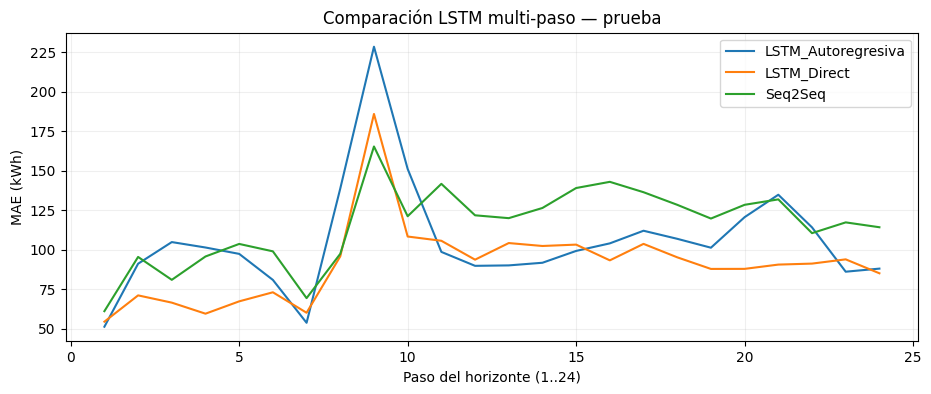

In [12]:
ar_names=['LSTM_Autoregresiva','LSTM_Direct','Seq2Seq']
plt.figure(figsize=(11,4))
for name in ar_names:
    r=RESULTS[name]
    plt.plot(np.arange(1,H+1),np.mean(np.abs(r.y-r.pred),axis=(0,1)),label=name)
plt.xlabel('Paso del horizonte (1..24)'); plt.ylabel('MAE (kWh)')
plt.title('Comparación LSTM multi-paso — prueba'); plt.legend();plt.grid(alpha=.2);plt.show()

## 6. LightGBM global, con rezagos y calendario
Un único regresor aprende en todos los clientes. Se entrena para **un paso** con rezagos 1–24 y 168 y atributos de calendario; para los 24 pasos del día se realimentan **sus predicciones** (no los valores reales del día futuro). Para ahorrar RAM se muestrean pares *(cliente, instante)* de los bloques permitidos. Se selecciona el número de árboles usando solo validación y posteriormente se reajusta una vez con train+val.

In [13]:
import lightgbm as lgb

def lgb_features(cids, tids, series=Y):
    cids=np.asarray(cids,dtype=np.int64); tids=np.asarray(tids,dtype=np.int64)
    lags=np.stack([series[cids,tids-lag] for lag in list(range(1,25))+[168]],axis=1)
    return np.concatenate([lags,cal_np[tids],cids[:,None].astype(np.float32)],axis=1).astype(np.float32)

def train_lgb(train_start,train_end,seed=SEED,n_samples=None,n_estimators=220,valid=True):
    rng=np.random.default_rng(seed)
    n_samples=n_samples or (90000 if QUICK_MODE else 400000)
    tmin=max(168,train_start)
    tt=rng.integers(tmin,train_end,size=n_samples)
    cc=rng.integers(0,len(clientes),size=n_samples)
    features=lgb_features(cc,tt); yy=Y[cc,tt]
    model=lgb.LGBMRegressor(n_estimators=n_estimators,learning_rate=.05,num_leaves=31,
            max_depth=-1,colsample_bytree=.9,random_state=seed,n_jobs=2,verbosity=-1)
    if valid:
        vcc=rng.integers(0,len(clientes),size=min(40000,n_samples//4))
        vtt=rng.integers(T_TR,T_VA,size=len(vcc))
        model.fit(features,yy,eval_set=[(lgb_features(vcc,vtt),Y[vcc,vtt])],
                  eval_metric='l1',callbacks=[lgb.early_stopping(stopping_rounds=25,verbose=False)])
    else: model.fit(features,yy)
    return model

class LightGBMAdapter:
    def __init__(self,model):self.model=model
    def predict(self,origin,horizon=24):
        # Cada nuevo lag 1..24 se rellena con el pronóstico si t >= origin.
        n=len(clientes); history=Y[:,origin-168:origin].copy()
        ids=np.arange(n,dtype=np.int64); predictions=[]
        for step in range(horizon):
            t=origin+step
            ff=np.concatenate([np.stack([history[:,-lag] for lag in list(range(1,25))+[168]],axis=1),
                               np.broadcast_to(cal_np[t],(n,N_CAL)),ids[:,None].astype('float32')],axis=1)
            p=np.asarray(self.model.predict(ff),dtype='float32')
            predictions.append(p)
            history=np.concatenate([history,p[:,None]],axis=1)
        return np.stack(predictions,axis=1)

t0=time.perf_counter()
LGB_VALID_MODEL=train_lgb(T0,T_TR,valid=True)
VALIDATION['LightGBM']=backtest(LightGBMAdapter(LGB_VALID_MODEL),'val','LightGBM')
best_trees=int(LGB_VALID_MODEL.best_iteration_ or LGB_VALID_MODEL.n_estimators)
print('LightGBM validation:',VALIDATION['LightGBM'].metrics(),'árboles óptimos:',best_trees)
LGB_FINAL_MODEL=train_lgb(T0,T_VA,valid=False,n_estimators=best_trees)
total=time.perf_counter()-t0
RESULTS['LightGBM']=backtest(LightGBMAdapter(LGB_FINAL_MODEL),'test','LightGBM')
MODEL_META['LightGBM']={'familia':'Árbol global','L':168,'estrategia':'Recursiva 1→24',
    'covariables':True,'parametros':np.nan,'entrenables':np.nan,
    'entrenamiento_s':total,'hardware':'CPU','nota_parametros':f'{best_trees} árboles; el conteo de pesos neuronales NO aplica'}
print('LightGBM prueba:',RESULTS['LightGBM'].metrics())

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

LightGBM validation: {'MAE': 151.8574881018574, 'RMSE': 1060.0063698308925, 'WAPE': 13.218570617418713, 'MAPE': 215.78652804326765, 'MASE': 11.38997484208637, 'fraccion_ceros': 0.007155797101449275} árboles óptimos: 61


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

LightGBM prueba: {'MAE': 136.69446005068178, 'RMSE': 933.9353153308462, 'WAPE': 17.340491365970035, 'MAPE': 193.64353943656323, 'MASE': 11.817485293585055, 'fraccion_ceros': 0.014067028985507246}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

## 7. StatsForecast: AutoETS y comprobación de las reglas naive
`StatsForecast` recibe columnas `unique_id, ds, y`, con una serie por cliente. Se invoca `AutoETS` como alternativa estadística. Para respetar el entrenamiento congelado, ajustamos el modelo con los datos **previos al bloque** y predecimos las 92 jornadas sin volver a ajustar pesos durante el bloque. Las reglas `Naive` y `SeasonalNaive` se computaron de manera vectorizada en la sección 4 (son equivalentes exactamente a sus reglas matemáticas en StatsForecast); aquí también se crean los modelos de la biblioteca y se comprueba su salida con un ejemplo de entrenamiento.

**Interpretación:** el naive estacional es un baseline actualizado automáticamente con valores observados hasta cada origen. El AutoETS congelado pronostica tres meses de una vez: no se le permite reajustarse diariamente con los valores reales de prueba; esto sigue el protocolo del PDF, aunque lo penaliza a largo plazo.

In [14]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, AutoETS

# Tabla larga: n_clientes × 26,304 horas. Puede utilizar ~300 MB de RAM.
long_df=hourly.stack().rename('y').reset_index()
long_df.columns=['ds','unique_id','y']
long_df['y']=long_df['y'].astype('float32')
long_df=long_df.sort_values(['unique_id','ds']).reset_index(drop=True)
print('Nixtla panel:',long_df.shape, '| IDs:',long_df.unique_id.nunique())

# Prueba corta de API StatsForecast, sin tocar prueba para calibración.
check_ids=clientes[:2]
check_cutoff=pd.Timestamp('2014-06-30 23:00')
check_df=long_df.loc[long_df.unique_id.isin(check_ids) & (long_df.ds<=check_cutoff)]
small_sf=StatsForecast(models=[Naive(),SeasonalNaive(season_length=24,alias='SeasonalNaive24'),SeasonalNaive(season_length=168,alias='SeasonalNaive168')],
                       freq='h',n_jobs=1)
small_out=small_sf.forecast(df=check_df,h=H)
display(small_out.head())
# Cada regla usa exactamente su último y conocido al corte.
for uid in check_ids:
    forecast=small_out.loc[small_out.unique_id==uid]
    row=Y[clientes.index(uid)]
    assert np.allclose(forecast['Naive'], row[T_TR-1], atol=1e-4)
    assert np.allclose(forecast['SeasonalNaive24'], row[T_TR-24:T_TR], atol=1e-4)
    # Algunas versiones asignan alias repetido; verificar columna 168 si está presente.
print('Comprobación de reglas Naive / SeasonalNaive24: correcta')

Nixtla panel: (2630400, 3) | IDs: 100


,unique_id,ds,Naive,SeasonalNaive24,SeasonalNaive168
0,MT_002,2014-07-01 00:00:00,30.049786,25.960171,24.893314
1,MT_002,2014-07-01 01:00:00,30.049786,21.337126,21.870554
2,MT_002,2014-07-01 02:00:00,30.049786,20.625889,20.625889
3,MT_002,2014-07-01 03:00:00,30.049786,20.270271,20.270269
4,MT_002,2014-07-01 04:00:00,30.049786,21.159317,21.159317


Comprobación de reglas Naive / SeasonalNaive24: correcta


### AutoETS con entrenamiento congelado


In [15]:
class LongTableAdapter:
    def __init__(self,fcst,model_col):
        self.values=fcst.pivot(index='ds',columns='unique_id',values=model_col).reindex(columns=clientes)
    def predict(self,origin,horizon=24):
        ts=idx[origin:origin+horizon]
        p=self.values.reindex(ts).to_numpy(dtype=np.float32).T
        if np.isnan(p).any(): raise RuntimeError('Faltan timestamps del pronóstico precomputado')
        return p

def autoets_block(cutoff_exclusive,block,model=None):
    model=AutoETS(season_length=24,model='ZZZ') if model is None else model
    df=long_df.loc[long_df.ds<idx[cutoff_exclusive]]
    n_hours=splits[block][1]-splits[block][0]
    t0=time.perf_counter()
    forecast=StatsForecast(models=[model],freq='h',n_jobs=2).forecast(df=df,h=n_hours)
    assert forecast.ds.min()==idx[cutoff_exclusive]
    return LongTableAdapter(forecast,'AutoETS'),time.perf_counter()-t0

if RUN_AUTOETS:
    auto_v,t_val=autoets_block(T_TR,'val')
    VALIDATION['AutoETS']=backtest(auto_v,'val','AutoETS')
    auto_t,t_final=autoets_block(T_VA,'test')
    RESULTS['AutoETS']=backtest(auto_t,'test','AutoETS')
    MODEL_META['AutoETS']={'familia':'StatsForecast','L':None,'estrategia':'H horizonte congelado',
      'covariables':False,'parametros':np.nan,'entrenables':np.nan,'entrenamiento_s':t_final,'hardware':'CPU'}
    print('AutoETS (val/test):',VALIDATION['AutoETS'].metrics(),RESULTS['AutoETS'].metrics())
else: print('AutoETS desactivado: no se incluirá en tabla, activar antes de entrega.')

AutoETS (val/test): {'MAE': 222.6363891784906, 'RMSE': 2270.088208987415, 'WAPE': 19.379583247083865, 'MAPE': 25.427921028339494, 'MASE': 1.6767085928919516, 'fraccion_ceros': 0.007155797101449275} {'MAE': 215.78202944644892, 'RMSE': 1808.6102831179694, 'WAPE': 27.373211885546173, 'MAPE': 31.956898041952186, 'MASE': 1.8882364545342536, 'fraccion_ceros': 0.014067028985507246}


## 8. NeuralForecast: N-HiTS, TCN, PatchTST, TFT y DeepAR probabilístico
Se requieren cuatro familias adicionales: residual (**NHITS**), convolucional causal (**TCN**), atención (**PatchTST** y **TFT**) y probabilística (**DeepAR**). Cada una se entrena globalmente con el mismo panel y se evalúa por la función única `backtest` (mediante un adaptador de predicciones). Para mantener **una sola actualización de pesos** antes del período evaluado, se utiliza `cross_validation(n_windows=92,step_size=24,refit=False)` de Nixtla: en validación inicia ajuste con datos anteriores a julio; en prueba se crea instancia nueva y entrena con datos anteriores a octubre. El framework mueve orígenes para la predicción sin reajustar los pesos de cada origen.

**DeepAR** produce una distribución; reportamos la predicción central y P10/P90, pinball loss y cobertura. Todas las fechas de características externas son conocidas a futuro. `TFT` cumple la elección «TFT o iTransformer» del PDF. Los demás modelos preservan el mínimo de 100 clientes.

In [17]:
from neuralforecast import NeuralForecast
from neuralforecast.models import NHITS, TCN, PatchTST, TFT, DeepAR
from neuralforecast.losses.pytorch import DistributionLoss

# En NeuralForecast se usan 7 columnas calendario, disponibles en todo el horizonte.
nixtla_calendar = calendar[CAL_COLS].reset_index()
nixtla_calendar = nixtla_calendar.rename(columns={nixtla_calendar.columns[0]:'ds'})
nf_df = long_df.merge(nixtla_calendar,on='ds',how='left',validate='many_to_one')
assert nf_df[CAL_COLS].notna().all().all()

def make_nf(name,steps=NF_STEPS,lookback=L,seed=SEED):
    common=dict(h=H,input_size=lookback,max_steps=steps,learning_rate=1e-3,
                batch_size=32,windows_batch_size=256,scaler_type='standard',
                random_seed=seed,alias=name)
    if name=='NHITS': return NHITS(**common,futr_exog_list=CAL_COLS)
    if name=='TCN': return TCN(**common,futr_exog_list=CAL_COLS)
    if name=='PatchTST': return PatchTST(**common,futr_exog_list=CAL_COLS)
    if name=='TFT': return TFT(**common,futr_exog_list=CAL_COLS,hidden_size=64)
    if name=='DeepAR':
        return DeepAR(**common,futr_exog_list=CAL_COLS,
          loss=DistributionLoss(distribution='StudentT',level=[80]),
          lstm_hidden_size=64,trajectory_samples=100)
    raise KeyError(name)

def nf_crossvalidate(name,until,block,lookback=L,steps=NF_STEPS,seed=SEED):
    # Todas las observaciones y covariables se incluyen en el objeto de CV;
    # refit=False exige ajustar una sola vez en el primer cutoff del bloque.
    df = nf_df.loc[nf_df.ds <= idx[until - 1]].copy()
    n_days=(splits[block][1]-splits[block][0])//24
    model=make_nf(name,steps=steps,lookback=lookback,seed=seed)
    runner=NeuralForecast(models=[model],freq='h')
    start=time.perf_counter()
    cv=runner.cross_validation(df=df,n_windows=n_days,step_size=24,refit=False,val_size=0)
    elapsed=time.perf_counter()-start
    assert pd.Timestamp(cv['ds'].min())==idx[splits[block][0]], 'CV tomó un bloque temporal erróneo'
    assert cv[['unique_id','ds']].duplicated().sum()==0,'Horizontes de CV superpuestos'
    return runner,cv,elapsed

class NixtlaCVAdapter(LongTableAdapter):
    def __init__(self,cv,name):
        self.name=name
        if name=='DeepAR':
            cols=[c for c in cv.columns if str(c).startswith(name)]
            point=next((c for c in cols if c==name),None)
            if point is None: point=next((c for c in cols if 'median' in str(c).lower()),None)
            if point is None: raise KeyError(f'No se encontró salida central DeepAR entre {cols}')
            self.low=LongTableAdapter(cv,next(c for c in cols if '-lo-80' in str(c)))
            self.high=LongTableAdapter(cv,next(c for c in cols if '-hi-80' in str(c)))
        else: point=name
        super().__init__(cv,point)
    def predict(self,origin,horizon=24):
        y=super().predict(origin,horizon)
        if self.name=='DeepAR':return y,self.low.predict(origin,horizon),self.high.predict(origin,horizon)
        return y

NF_MODELS=['NHITS','TCN','PatchTST','TFT','DeepAR']
NF_FITTED={}
if RUN_NEURALFORECAST:
    for nf_name in NF_MODELS:
        print('\nNeuralForecast:',nf_name,'→ validación')
        nf_val,cv_val,vt=nf_crossvalidate(nf_name,T_VA,'val')
        VALIDATION[nf_name]=backtest(NixtlaCVAdapter(cv_val,nf_name),'val',nf_name)
        print('Validación:',VALIDATION[nf_name].metrics())
        del nf_val,cv_val; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
        print('NeuralForecast:',nf_name,'→ prueba sin refit entre orígenes')
        nf_final,cv_test,tt=nf_crossvalidate(nf_name,T_END,'test')
        RESULTS[nf_name]=backtest(NixtlaCVAdapter(cv_test,nf_name),'test',nf_name)
        fitted_model=nf_final.models[0]
        params=sum(p.numel() for p in fitted_model.parameters())
        trainable=sum(p.numel() for p in fitted_model.parameters() if p.requires_grad)
        NF_FITTED[nf_name]=nf_final
        MODEL_META[nf_name]={'familia':'NeuralForecast','L':L,'estrategia':'Directa/probabilística',
           'covariables':True,'parametros':params,'entrenables':trainable,
           'entrenamiento_s':tt,'hardware':str(DEVICE)}
        print('Prueba:',RESULTS[nf_name].metrics())
        del cv_test;gc.collect()
else: print('NeuralForecast desactivado; activar antes de entregar el laboratorio completo.')


NeuralForecast: NHITS → validación


INFO:lightning_fabric.utilities.seed:Seed set to 2026
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name                ┃ Type          ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss                │ MAE           │      0 │ train │     0 │
│ 1 │ hist_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 2 │ futr_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 3 │ stat_cat_embeddings │ ModuleList    │      0 │ train │     0 │
│ 4 │ padder_train        │ ConstantPad1d │      0 │ train │     0 │
│ 5 │ scaler              │ TemporalNorm  │      0 │ train │     0 │
│ 6 │ blocks              │ ModuleList    │  4.2 M │ train │     0 │
└───┴─────────────────────┴───────────────┴────────┴───────┴───────┘

Trainable params: 4.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.2 M                                                                                                
Total estimated model params size (MB): 16.775                                                                     
Modules in train mode: 37                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

...

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Output()

Prueba: {'MAE': 3765.634396462111, 'RMSE': 192199.98801002355, 'WAPE': 477.69273688956156, 'MAPE': 573.9659814024258, 'MASE': 31.65714340917002, 'fraccion_ceros': 0.014067028985507246}

NeuralForecast: PatchTST → validación


INFO:lightning_fabric.utilities.seed:Seed set to 2026


Exception: PatchTST does not support future exogenous variables.

## 9. Chronos-Bolt zero-shot (sin entrenamiento)
Se usa `BaseChronosPipeline.predict_quantiles(inputs, prediction_length, quantile_levels)` con un tensor `(n_series, contexto)` y cuantiles P10/P50/P90. Es el **único modelo sin entrenamiento** del laboratorio. Se fija el modelo `amazon/chronos-bolt-small` (variante ligera de la familia Chronos-Bolt); se debe registrar esta variante exacta en el PDF. La inferencia usa solo historia anterior al origen. Requiere internet para descargar los pesos del repositorio de Hugging Face.

In [18]:
from chronos import BaseChronosPipeline
class ChronosAdapter:
    def __init__(self,pipeline,context_size=512):self.pipeline,self.context_size=pipeline,context_size
    def predict(self,origin,horizon=24):
        ctx=torch.from_numpy(Y[:,max(0,origin-self.context_size):origin].copy())
        q,avg=self.pipeline.predict_quantiles(ctx,prediction_length=horizon,
                                               quantile_levels=[.1,.5,.9])
        if isinstance(q,list): q=torch.stack(q).squeeze(1)
        if isinstance(avg,list):avg=torch.stack(avg).squeeze(1)
        q=np.asarray(q.detach().cpu() if hasattr(q,'detach') else q,dtype=np.float32)
        avg=np.asarray(avg.detach().cpu() if hasattr(avg,'detach') else avg,dtype=np.float32)
        assert q.shape==(len(clientes),horizon,3),q.shape
        return avg,q[:,:,0],q[:,:,2]

CHRONOS_ADAPTER=None
if RUN_CHRONOS:
    from_pretrained_start=time.perf_counter()
    pipeline=BaseChronosPipeline.from_pretrained('amazon/chronos-bolt-small',
                                               device_map='cuda' if DEVICE.type=='cuda' else 'cpu')
    CHRONOS_ADAPTER=ChronosAdapter(pipeline,512)
    VALIDATION['Chronos-Bolt-small']=backtest(CHRONOS_ADAPTER,'val','Chronos-Bolt-small')
    RESULTS['Chronos-Bolt-small']=backtest(CHRONOS_ADAPTER,'test','Chronos-Bolt-small')
    MODEL_META['Chronos-Bolt-small']={'familia':'Fundacional zero-shot','L':512,
      'estrategia':'Cuantiles directos','covariables':False,
      'parametros':sum(p.numel() for p in pipeline.model.parameters()),
      'entrenables':0,'entrenamiento_s':0.,'hardware':str(DEVICE)}
    print('Chronos validación:', VALIDATION['Chronos-Bolt-small'].metrics())
    print('Chronos prueba:', RESULTS['Chronos-Bolt-small'].metrics())
else: print('Chronos desactivado; activar para entregable completo.')

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  191MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Chronos validación: {'MAE': 70.79495547186367, 'RMSE': 735.1316271734077, 'WAPE': 6.162410098830004, 'MAPE': 10.79688546054252, 'MASE': 0.6826958581002333, 'fraccion_ceros': 0.007155797101449275, 'pinball_P10_P90': 16.94175910949707, 'cobertura_P10_P90': 0.8107382246376812}
Chronos prueba: {'MAE': 57.1577375549173, 'RMSE': 566.2043140515576, 'WAPE': 7.250793149934105, 'MAPE': 10.569992694209912, 'MASE': 0.6833936584197143, 'fraccion_ceros': 0.014067028985507246, 'pinball_P10_P90': 13.926432609558105, 'cobertura_P10_P90': 0.8057201086956521}
